## Reactivation Feature Validation  Full POS vs NEG Metrics

Lead-level comparison: **POS** (reactivated) vs **NEG** (never reactivated, NI ≥ 90 days).

Goal: find which metrics distinguish leads that can be reactivated.

Data: `reactivation_analysis/analysis_final.xlsx` (one row per leadId).

Also see: `reactivation_results_summary.ipynb` (charts / cross-project overview).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

OUT = Path("/Users/lekhanigam/RM Feature Analysis/reactivation_analysis")

print("Loading analysis_final.xlsx (lead-level metrics)...")
df = pd.read_excel(OUT / "analysis_final.xlsx")
print(f"Rows: {len(df):,} | Columns: {len(df.columns)}")
print(df["cohort_label"].value_counts().to_string())
display(df.head(3))

# Derived flags used in comparisons
df["any_pre_ni_call"] = (df["pre_ni_calls"].fillna(0) > 0).astype(int)
df["any_post_ni_call"] = (df["post_ni_calls"].fillna(0) > 0).astype(int)
df["any_post_ni_inbound"] = (df["post_ni_inbound"].fillna(0) > 0).astype(int)
df["pre_ni_calls_ge5"] = (df["pre_ni_calls"].fillna(0) >= 5).astype(int)
df["any_pre_web"] = (df["pre_ni_web_sessions"].fillna(0) > 0).astype(int)
df["any_post_web"] = (df["post_ni_web_sessions"].fillna(0) > 0).astype(int)
df["viewed_price_flag"] = df["viewed_price"].fillna(0).astype(int)
df["any_post_wa"] = (df["post_ni_wa"].fillna(0) > 0).astype(int)
df["any_post_wa_inbound"] = (df["post_ni_wa_inbound"].fillna(0) > 0).astype(int)
df["is_oscillator"] = (df["ni_count"].fillna(0) >= 2).astype(int)

pos = df[df["cohort_label"] == "POS"]
neg = df[df["cohort_label"] == "NEG"]
print(f"\nPOS leads: {len(pos):,} | NEG leads: {len(neg):,}")

Loading analysis_final.xlsx (lead-level metrics)...
Rows: 986,426 | Columns: 29
cohort_label
NEG    846296
POS    140130


,leadid,masterleadid,project_name,born_source,cohort_label,born_ts,first_ni_ts,ni_count,first_ni_reason,ni_cancelled_reason,...,pre_ni_calls,post_ni_calls,post_ni_inbound,days_since_last_call,pre_ni_web_sessions,post_ni_web_sessions,viewed_price,pre_ni_wa,post_ni_wa,post_ni_wa_inbound
0,1193270,929307,Loft,99-acres,POS,2026-05-24 07:57:27.009,2026-05-30 07:06:46.034,3,Multiple Call Fails by Customer,Multiple Call Fails by Customer,...,11,0,0,9.0,0,0,0,7,0,0
1,810134,648816,Loft,Channel Partner,POS,2025-08-09 08:15:52.560,2025-08-11 12:15:18.031,6,On Site Visit,Budget,...,3,0,0,29.0,0,0,0,5,4,0
2,793520,635788,Loft,99-acres,POS,2025-07-28 11:38:40.837,2025-07-29 04:38:04.737,3,Post Call,Not looking for Property,...,1,0,0,90.0,0,0,0,5,26,0



POS leads: 140,130 | NEG leads: 846,296


## 1. What to take into the Reactivation Model

Shortlist from POS vs NEG patterns (also in `model_metrics_to_use.xlsx`).

In [2]:
reco = pd.read_excel(OUT / "model_metrics_to_use.xlsx")
display(reco)

print("\nUse these first for scoring who can be reactivated:")
for _, r in reco[reco["priority"] == "HIGH"].iterrows():
    print(f"  • [{r['priority']}] {r['metric']}")
    print(f"      {r['why']}")

,priority,metric,why,use_in_model
0,HIGH,any_post_ni_inbound / post_ni_inbound,POS 16.8% vs NEG 1.6% (+15 pp). Customer-initi...,Yes — Scenario B (post-NI window)
1,HIGH,any_post_ni_call / post_ni_calls,POS 25.4% vs NEG 5.0% (+20 pp). Strongest enga...,Yes
2,HIGH,days_since_last_call,POS median 30d vs NEG 90d — recency of contact.,Yes (capped at W)
3,HIGH,stage_before_ni + had_pre/had_sv before NI,Deeper funnel before NI → higher return rate.,Yes — available at NI time
4,HIGH,ni_reason_tier (SOFT vs HARD/SYSTEM),SOFT ~20.5% vs HARD ~14% vs SYSTEM ~8.7%.,Yes — at NI time
5,HIGH,project_name + born_source,Large rate spread; needed as features/controls.,Yes
6,HIGH,any_post_web,POS 6.0% vs NEG 0.3% — rare but high lift.,Yes when web coverage exists
7,HIGH,any_post_wa_inbound,POS 10.9% vs NEG 6.1% (+4.8 pp).,Yes — inbound only
8,MEDIUM,pre_ni_calls (≥5),+10 pp; intensity before NI.,Yes
9,MEDIUM,cross_project / project-fit NI flag,~154K customers NI on A then positive on B; 29...,Separate play / feature for multi-project



Use these first for scoring who can be reactivated:
  • [HIGH] any_post_ni_inbound / post_ni_inbound
      POS 16.8% vs NEG 1.6% (+15 pp). Customer-initiated contact after NI.
  • [HIGH] any_post_ni_call / post_ni_calls
      POS 25.4% vs NEG 5.0% (+20 pp). Strongest engagement separator.
  • [HIGH] days_since_last_call
      POS median 30d vs NEG 90d — recency of contact.
  • [HIGH] stage_before_ni + had_pre/had_sv before NI
      Deeper funnel before NI → higher return rate.
  • [HIGH] ni_reason_tier (SOFT vs HARD/SYSTEM)
      SOFT ~20.5% vs HARD ~14% vs SYSTEM ~8.7%.
  • [HIGH] project_name + born_source
      Large rate spread; needed as features/controls.
  • [HIGH] any_post_web
      POS 6.0% vs NEG 0.3% — rare but high lift.
  • [HIGH] any_post_wa_inbound
      POS 10.9% vs NEG 6.1% (+4.8 pp).


## 2. Full binary metric table (POS % vs NEG %)

,category,metric,column,POS_yes,POS_n,POS_%,NEG_yes,NEG_n,NEG_%,diff_pp,POS_pct,NEG_pct
0,call,Any call after NI (≤90d),any_post_ni_call,35596,140130,25.40,42524,846296,5.02,20.38,25.40,5.02
1,call,Inbound call after NI,any_post_ni_inbound,23534,140130,16.79,13834,846296,1.63,15.16,16.79,1.63
2,call,≥5 calls before NI,pre_ni_calls_ge5,61571,140130,43.94,285893,846296,33.78,10.16,43.94,33.78
3,call,Any call before NI,any_pre_ni_call,133821,140130,95.50,795900,846296,94.05,1.45,95.50,94.05
4,stage,2+ NI events (oscillator),is_oscillator,138224,140130,98.64,1435,846296,0.17,98.47,98.64,0.17
5,stage,Pre Site Visit before NI,had_pre_before_ni,10463,140130,7.47,31610,846296,3.74,3.73,7.47,3.74
6,stage,Post Site Visit before NI,had_sv_before_ni,5917,140130,4.22,16058,846296,1.90,2.33,4.22,1.90
7,stage,NI reason = Personal Call,is_ni_personal_call,19047,140130,13.59,98935,846296,11.69,1.90,13.59,11.69
8,website,Any website session after NI,any_post_web,8377,140130,5.98,2156,846296,0.25,5.72,5.98,0.25
9,website,Viewed price / price sheet,viewed_price_flag,53471,140130,38.16,366970,846296,43.36,-5.20,38.16,43.36


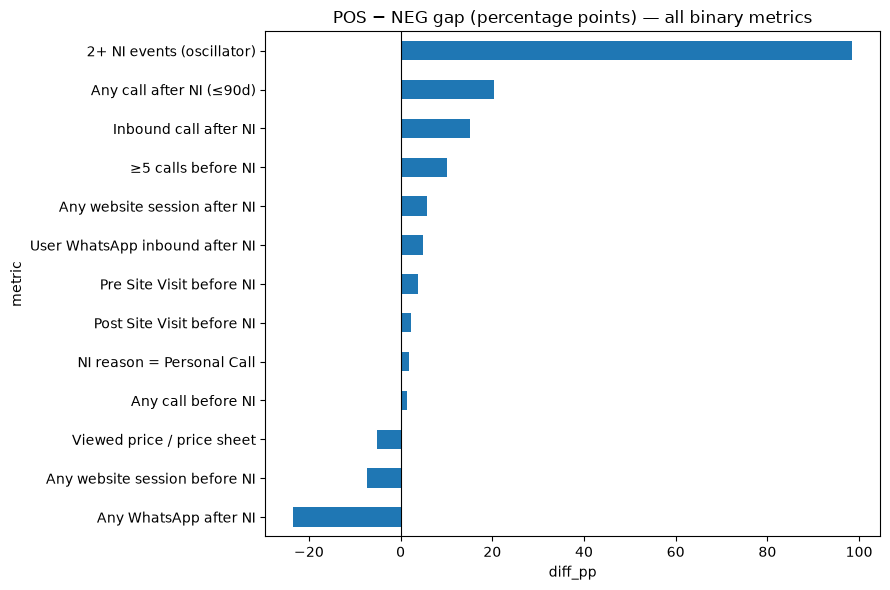

In [3]:
metrics = pd.read_excel(OUT / "pos_vs_neg_metrics.xlsx", sheet_name="1_Binary_Metrics")
display(metrics)

plot = metrics.sort_values("diff_pp")
plot.set_index("metric")["diff_pp"].plot(
    kind="barh", figsize=(9, 6),
    title="POS − NEG gap (percentage points) — all binary metrics"
)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("diff_pp"); plt.tight_layout(); plt.show()

## 3. Numeric metrics (medians / means by cohort)

In [4]:
nums = pd.read_excel(OUT / "pos_vs_neg_metrics.xlsx", sheet_name="2_Numeric_Metrics")
display(nums)

print("\nKey read: lower days_since_last_call for POS = more recent contact before scoring.")

,category,metric,column,POS_n,NEG_n,POS_median,NEG_median,POS_mean,NEG_mean,POS_pct_zero,NEG_pct_zero,diff_median
0,call,Calls before NI,pre_ni_calls,140130,846296,4,3.0,5.40,4.31,4.5,6.0,1.0
1,call,Calls after NI,post_ni_calls,140130,846296,0,0.0,0.33,0.07,74.6,95.0,0.0
2,call,Inbound calls after NI,post_ni_inbound,140130,846296,0,0.0,0.19,0.02,83.2,98.4,0.0
3,call,Days since last call,days_since_last_call,134269,796687,30,90.0,46.34,94.52,33.2,5.9,-60.0
4,website,Website sessions before NI,pre_ni_web_sessions,140130,846296,0,0.0,0.39,0.45,64.1,56.8,0.0
5,website,Website sessions after NI,post_ni_web_sessions,140130,846296,0,0.0,0.06,0.00,94.0,99.7,0.0
6,whatsapp,WhatsApp msgs before NI,pre_ni_wa,140130,846296,4,4.0,8.56,7.36,13.9,8.5,0.0
7,whatsapp,WhatsApp msgs after NI,post_ni_wa,140130,846296,4,14.0,11.05,20.04,31.4,8.0,-10.0
8,whatsapp,WA inbound count after NI,post_ni_wa_inbound,140130,846296,0,0.0,0.25,0.14,89.1,93.9,0.0
9,stage,NI event count,ni_count,140130,846296,2,1.0,2.40,1.00,0.0,0.0,1.0



Key read: lower days_since_last_call for POS = more recent contact before scoring.


## 4. Stage metrics

,category,metric,column,POS_yes,POS_n,POS_%,NEG_yes,NEG_n,NEG_%,diff_pp,POS_pct,NEG_pct
4,stage,2+ NI events (oscillator),is_oscillator,138224,140130,98.64,1435,846296,0.17,98.47,98.64,0.17
5,stage,Pre Site Visit before NI,had_pre_before_ni,10463,140130,7.47,31610,846296,3.74,3.73,7.47,3.74
6,stage,Post Site Visit before NI,had_sv_before_ni,5917,140130,4.22,16058,846296,1.90,2.33,4.22,1.90
7,stage,NI reason = Personal Call,is_ni_personal_call,19047,140130,13.59,98935,846296,11.69,1.90,13.59,11.69


,stage_before_ni,leads,POS,NEG,POS_%,NEG_%,reactivation_rate_pct,POS_pct,NEG_pct
0,Flat Blocked,706,321,385,45.47,54.53,45.47,45.47,54.53
1,Post Site Visit,21408,5657,15751,26.42,73.58,26.42,26.42,73.58
2,Pre Site Visit,31667,6947,24720,21.94,78.06,21.94,21.94,78.06
3,Lead Initiated,317665,52901,264764,16.65,83.35,16.65,16.65,83.35
4,New Lead,614560,74183,540377,12.07,87.93,12.07,12.07,87.93


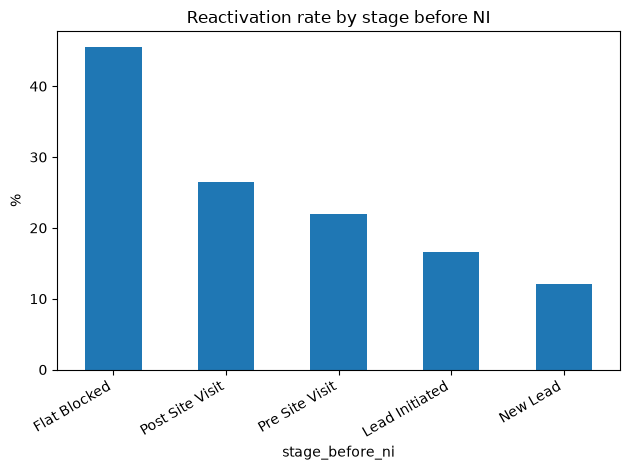

,ni_reason_tier,leads,POS,NEG,POS_%,NEG_%,reactivation_rate_pct,POS_pct,NEG_pct
0,SOFT,42339,8680,33659,20.50,79.50,20.50,20.50,79.50
1,MEDIUM,833189,121455,711734,14.58,85.42,14.58,14.58,85.42
2,HARD,5725,800,4925,13.97,86.03,13.97,13.97,86.03
3,SYSTEM,105173,9195,95978,8.74,91.26,8.74,8.74,91.26


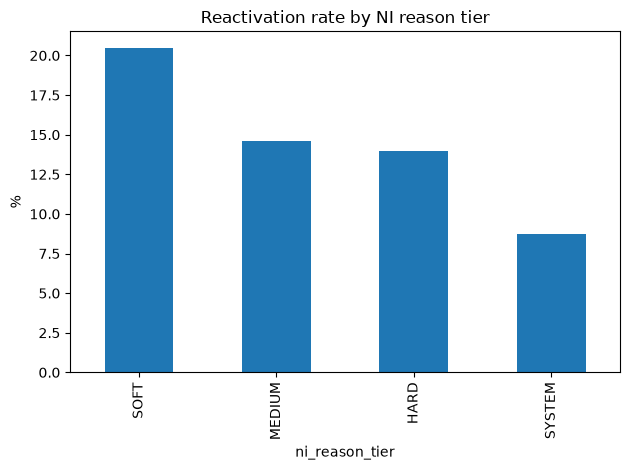

In [5]:
stage_m = metrics[metrics["category"] == "stage"]
display(stage_m)

by_stage = pd.read_excel(OUT / "pos_vs_neg_metrics.xlsx", sheet_name="3_By_Stage_Before_NI")
display(by_stage)
by_stage.set_index("stage_before_ni")["reactivation_rate_pct"].plot(
    kind="bar", title="Reactivation rate by stage before NI", ylabel="%"
)
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

by_tier = pd.read_excel(OUT / "pos_vs_neg_metrics.xlsx", sheet_name="4_By_NI_Tier")
display(by_tier)
by_tier.set_index("ni_reason_tier")["reactivation_rate_pct"].plot(
    kind="bar", title="Reactivation rate by NI reason tier", ylabel="%"
)
plt.tight_layout(); plt.show()

## 5. Call metrics

,category,metric,column,POS_yes,POS_n,POS_%,NEG_yes,NEG_n,NEG_%,diff_pp,POS_pct,NEG_pct
0,call,Any call after NI (≤90d),any_post_ni_call,35596,140130,25.40,42524,846296,5.02,20.38,25.40,5.02
1,call,Inbound call after NI,any_post_ni_inbound,23534,140130,16.79,13834,846296,1.63,15.16,16.79,1.63
2,call,≥5 calls before NI,pre_ni_calls_ge5,61571,140130,43.94,285893,846296,33.78,10.16,43.94,33.78
3,call,Any call before NI,any_pre_ni_call,133821,140130,95.50,795900,846296,94.05,1.45,95.50,94.05


,category,metric,column,POS_yes,POS_n,POS_%,NEG_yes,NEG_n,NEG_%,diff_pp,POS_pct,NEG_pct
0,call,Any call after NI (≤90d),any_post_ni_call,35596,140130,25.40,42524,846296,5.02,20.38,25.40,5.02
1,call,Inbound call after NI,any_post_ni_inbound,23534,140130,16.79,13834,846296,1.63,15.16,16.79,1.63
2,call,≥5 calls before NI,pre_ni_calls_ge5,61571,140130,43.94,285893,846296,33.78,10.16,43.94,33.78
3,call,Any call before NI,any_pre_ni_call,133821,140130,95.50,795900,846296,94.05,1.45,95.50,94.05


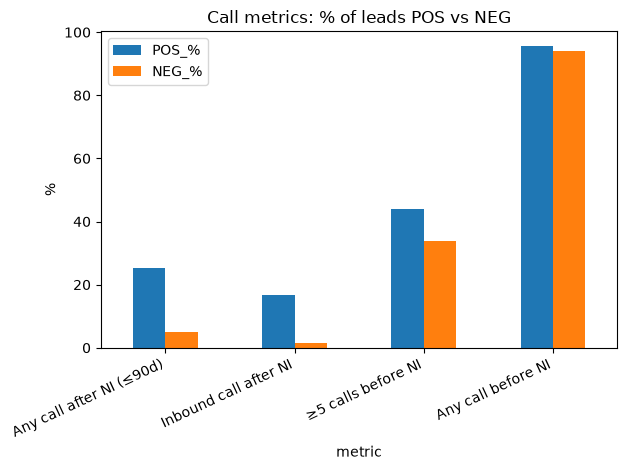

,category,metric,column,POS_n,NEG_n,POS_median,NEG_median,POS_mean,NEG_mean,POS_pct_zero,NEG_pct_zero,diff_median
0,call,Calls before NI,pre_ni_calls,140130,846296,4,3.0,5.40,4.31,4.5,6.0,1.0
1,call,Calls after NI,post_ni_calls,140130,846296,0,0.0,0.33,0.07,74.6,95.0,0.0
2,call,Inbound calls after NI,post_ni_inbound,140130,846296,0,0.0,0.19,0.02,83.2,98.4,0.0
3,call,Days since last call,days_since_last_call,134269,796687,30,90.0,46.34,94.52,33.2,5.9,-60.0


Takeaway: post-NI call / inbound call are the strongest reactivation separators.


In [6]:
call_m = metrics[metrics["category"] == "call"]
display(call_m)

call_m = metrics[metrics["category"] == "call"].copy()
display(call_m)

call_m.set_index("metric")[["POS_%", "NEG_%"]].plot(
    kind="bar", title="Call metrics: % of leads POS vs NEG", ylabel="%"
)
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()

display(nums[nums["category"] == "call"])
print("Takeaway: post-NI call / inbound call are the strongest reactivation separators.")

## 6. Website metrics

,category,metric,column,POS_yes,POS_n,POS_%,NEG_yes,NEG_n,NEG_%,diff_pp,POS_pct,NEG_pct
8,website,Any website session after NI,any_post_web,8377,140130,5.98,2156,846296,0.25,5.72,5.98,0.25
9,website,Viewed price / price sheet,viewed_price_flag,53471,140130,38.16,366970,846296,43.36,-5.20,38.16,43.36
10,website,Any website session before NI,any_pre_web,50276,140130,35.88,365518,846296,43.19,-7.31,35.88,43.19


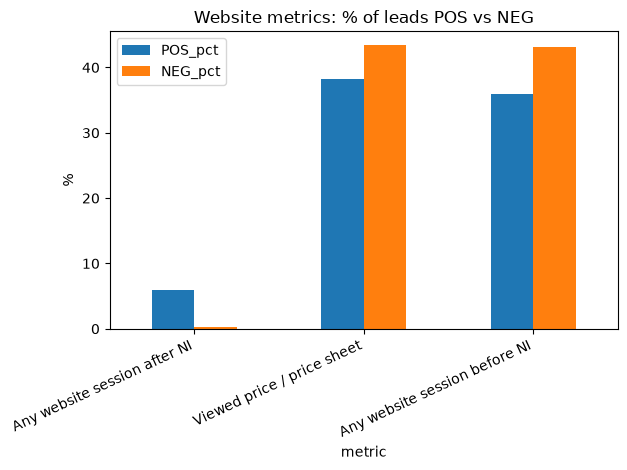

,category,metric,column,POS_n,NEG_n,POS_median,NEG_median,POS_mean,NEG_mean,POS_pct_zero,NEG_pct_zero,diff_median
4,website,Website sessions before NI,pre_ni_web_sessions,140130,846296,0,0.0,0.39,0.45,64.1,56.8,0.0
5,website,Website sessions after NI,post_ni_web_sessions,140130,846296,0,0.0,0.06,0.00,94.0,99.7,0.0


Takeaway: post-NI website return helps; pre-NI browsing is higher in NEG — do not treat as a chase signal.


In [7]:
web_m = metrics[metrics["category"] == "website"]
display(web_m)
web_m.set_index("metric")[["POS_pct", "NEG_pct"]].plot(
    kind="bar", title="Website metrics: % of leads POS vs NEG", ylabel="%"
)
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()
display(nums[nums["category"] == "website"])
print("Takeaway: post-NI website return helps; pre-NI browsing is higher in NEG — do not treat as a chase signal.")

## 7. WhatsApp metrics

,category,metric,column,POS_yes,POS_n,POS_%,NEG_yes,NEG_n,NEG_%,diff_pp,POS_pct,NEG_pct
11,whatsapp,User WhatsApp inbound after NI,any_post_wa_inbound,15273,140130,10.90,51357,846296,6.07,4.83,10.90,6.07
12,whatsapp,Any WhatsApp after NI,any_post_wa,96113,140130,68.59,778462,846296,91.98,-23.40,68.59,91.98


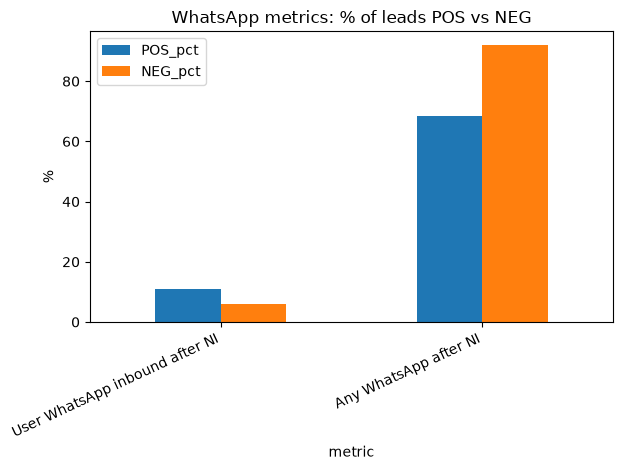

,category,metric,column,POS_n,NEG_n,POS_median,NEG_median,POS_mean,NEG_mean,POS_pct_zero,NEG_pct_zero,diff_median
6,whatsapp,WhatsApp msgs before NI,pre_ni_wa,140130,846296,4,4.0,8.56,7.36,13.9,8.5,0.0
7,whatsapp,WhatsApp msgs after NI,post_ni_wa,140130,846296,4,14.0,11.05,20.04,31.4,8.0,-10.0
8,whatsapp,WA inbound count after NI,post_ni_wa_inbound,140130,846296,0,0.0,0.25,0.14,89.1,93.9,0.0


Takeaway: use user inbound WA after NI; ignore total WA volume (NEG inflated by automation).


In [11]:
wa_m = metrics[metrics["category"] == "whatsapp"]
display(wa_m)
wa_m.set_index("metric")[["POS_pct", "NEG_pct"]].plot(
    kind="bar", title="WhatsApp metrics: % of leads POS vs NEG", ylabel="%"
)
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()
display(nums[nums["category"] == "whatsapp"])
print("Takeaway: use user inbound WA after NI; ignore total WA volume (NEG inflated by automation).")

## 8. Project & source (controls)

,project_name,leads,POS,NEG,POS_%,NEG_%,reactivation_rate_pct,POS_pct,NEG_pct
0,Legacy,13509,5996,7513,44.39,55.61,44.39,44.39,55.61
1,Loft,292271,48796,243475,16.70,83.30,16.70,16.70,83.30
2,Broadway,162106,23791,138315,14.68,85.32,14.68,14.68,85.32
3,Spectra,150719,21864,128855,14.51,85.49,14.51,14.51,85.49
4,Landmark,182235,22087,160148,12.12,87.88,12.12,12.12,87.88
5,Springs,126947,13186,113761,10.39,89.61,10.39,10.39,89.61
6,Spire,58639,4410,54229,7.52,92.48,7.52,7.52,92.48


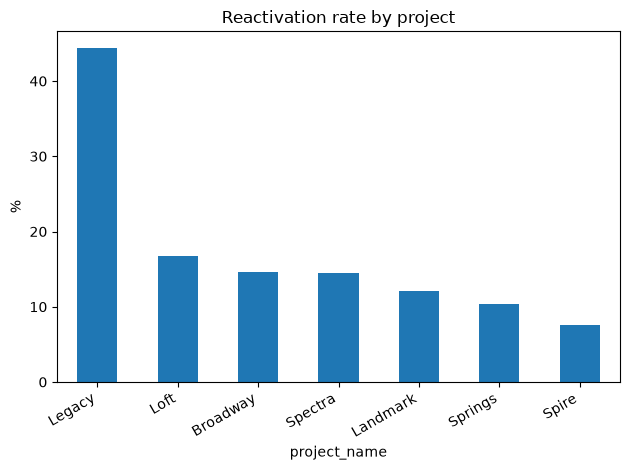

,born_source,leads,POS,NEG,POS_%,NEG_%,reactivation_rate_pct,POS_pct,NEG_pct
0,Self Generated Lead,1461,415,1046,28.41,71.59,28.41,28.41,71.59
1,Lead Referral,1926,528,1398,27.41,72.59,27.41,27.41,72.59
2,magic-bricks-vl,1422,362,1060,25.46,74.54,25.46,25.46,74.54
3,Pre-launch Web,10966,2695,8271,24.58,75.42,24.58,24.58,75.42
4,Executive Referral,15857,3641,12216,22.96,77.04,22.96,22.96,77.04
5,Customer Referral,1895,384,1511,20.26,79.74,20.26,20.26,79.74
6,Whatsapp,69353,13811,55542,19.91,80.09,19.91,19.91,80.09
7,Walk In,5867,1147,4720,19.55,80.45,19.55,19.55,80.45
8,housing.com,28980,5579,23401,19.25,80.75,19.25,19.25,80.75
9,Channel Partner,73808,13957,59851,18.91,81.09,18.91,18.91,81.09


In [12]:
by_proj = pd.read_excel(OUT / "pos_vs_neg_metrics.xlsx", sheet_name="5_By_Project")
display(by_proj)
by_proj.set_index("project_name")["reactivation_rate_pct"].plot(
    kind="bar", title="Reactivation rate by project", ylabel="%"
)
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

by_src = pd.read_excel(OUT / "pos_vs_neg_metrics.xlsx", sheet_name="6_By_Born_Source")
display(by_src.head(20))


## 9. Lead-level sample (POS and NEG side by side)

Sample of leadIds with metrics — full table is `analysis_final.xlsx`.

In [13]:
sample = pd.read_excel(OUT / "pos_vs_neg_metrics.xlsx", sheet_name="8_Lead_Sample_POS_NEG")
print("Sample rows:", len(sample))
print("POS sample:")
display(sample[sample["cohort_label"] == "POS"].head(10))
print("NEG sample:")
display(sample[sample["cohort_label"] == "NEG"].head(10))

Sample rows: 10000
POS sample:


,leadid,masterleadid,project_name,born_source,cohort_label,first_ni_ts,first_ni_reason,ni_cancelled_reason,ni_reason_tier,stage_before_ni,...,days_since_last_call,pre_ni_web_sessions,post_ni_web_sessions,viewed_price,pre_ni_wa,post_ni_wa,post_ni_wa_inbound,is_reactivated,first_reactivation_ts,reactivation_stage
0,1193270,929307,Loft,99-acres,POS,2026-05-30 07:06:46.034,Multiple Call Fails by Customer,Multiple Call Fails by Customer,MEDIUM,Lead Initiated,...,9.0,0,0,0,7,0,0,True,2026-06-09 06:42:37.727,Lead Initiated
1,810134,648816,Loft,Channel Partner,POS,2025-08-11 12:15:18.031,On Site Visit,Budget,SOFT,Post Site Visit,...,29.0,0,0,0,5,4,0,True,2025-09-09 15:26:22.864,Post Site Visit
2,793520,635788,Loft,99-acres,POS,2025-07-29 04:38:04.737,Post Call,Not looking for Property,MEDIUM,New Lead,...,90.0,0,0,0,5,26,0,True,2026-04-09 00:53:19.209,Lead Initiated
3,1248805,976922,Legacy,BGD,POS,2026-06-29 14:32:39.334,Multiple Call Fails by Customer,Multiple Call Fails by Customer,MEDIUM,Lead Initiated,...,10.0,0,0,0,0,0,0,True,2026-07-10 11:29:40.470,Lead Initiated
4,1253166,980043,Legacy,Pre-launch Web,POS,2026-06-28 11:00:15.671,Personal Call,Others,HARD,New Lead,...,NaN,0,0,0,0,0,0,True,2026-06-28 12:33:35.773,New Lead
5,1261424,986695,Landmark,99-acres,POS,2026-07-10 09:49:56.551,Post Call,Not looking for Property,MEDIUM,New Lead,...,0.0,0,0,0,2,0,0,True,2026-07-10 09:49:56.716,Lead Initiated
6,1165654,740545,Legacy,Whatsapp,POS,2026-05-02 06:52:33.753,Post Call,Budget,MEDIUM,New Lead,...,53.0,0,0,0,0,0,0,True,2026-06-25 04:30:50.916,Lead Initiated
7,1127932,853437,Loft,BGD,POS,2026-04-09 11:38:05.153,Post Call,Others,MEDIUM,New Lead,...,0.0,0,1,1,1,1,0,True,2026-04-09 11:40:50.803,Lead Initiated
8,1256522,982841,Spectra,Web Lead,POS,2026-07-04 12:19:20.242,Post Call,Not looking for Property,MEDIUM,Lead Initiated,...,0.0,1,0,1,2,0,0,True,2026-07-05 13:41:21.062,Lead Initiated
9,954401,763515,Loft,FIM Forms,POS,2025-11-15 13:42:10.723,Personal Call,Customer Not Responding,MEDIUM,Pre Site Visit,...,90.0,0,0,0,10,21,0,True,2026-04-05 13:13:03.755,Pre Site Visit


NEG sample:


,leadid,masterleadid,project_name,born_source,cohort_label,first_ni_ts,first_ni_reason,ni_cancelled_reason,ni_reason_tier,stage_before_ni,...,days_since_last_call,pre_ni_web_sessions,post_ni_web_sessions,viewed_price,pre_ni_wa,post_ni_wa,post_ni_wa_inbound,is_reactivated,first_reactivation_ts,reactivation_stage
5000,947820,757966,Loft,Repp_tech,NEG,2025-11-02 10:54:17.787,Personal Call,Customer Not Responding,MEDIUM,Lead Initiated,...,90.0,0,0,0,5,30,0,False,NaN,NaN
5001,947778,757931,Landmark,99-acres,NEG,2025-11-02 11:56:21.647,Multiple Call Fails by Customer,Multiple Call Fails by Customer,MEDIUM,New Lead,...,90.0,0,0,0,5,13,0,False,NaN,NaN
5002,947625,757810,Landmark,my-gate,NEG,2025-11-02 12:10:43.999,Multiple Call Fails by Customer,Multiple Call Fails by Customer,MEDIUM,New Lead,...,90.0,0,0,0,6,12,0,False,NaN,NaN
5003,890533,710398,Loft,Web Lead,NEG,2025-11-02 12:34:37.881,Post Call,Rural Leads,MEDIUM,New Lead,...,89.0,1,0,1,22,0,0,False,NaN,NaN
5004,944785,755533,Landmark,99-acres,NEG,2025-11-02 12:39:46.485,Post Call,Not looking for Property,MEDIUM,Lead Initiated,...,90.0,0,0,0,7,13,0,False,NaN,NaN
5005,932629,745035,Broadway,Web Lead,NEG,2025-11-03 01:18:42.958,Multiple Call Fails by Customer,Multiple Call Fails by Customer,MEDIUM,Lead Initiated,...,90.0,1,0,1,1,26,0,False,NaN,NaN
5006,951962,761411,Landmark,Web Lead,NEG,2025-11-03 05:11:19.260,Post Call,Rural Leads,MEDIUM,New Lead,...,90.0,2,0,1,3,2,0,False,NaN,NaN
5007,917631,69056,Broadway,99-acres,NEG,2025-11-03 05:30:50.497,Multiple Call Fails by Customer,Multiple Call Fails by Customer,MEDIUM,Lead Initiated,...,90.0,0,0,0,13,29,0,False,NaN,NaN
5008,914451,729835,Loft,Web Lead,NEG,2025-11-03 05:59:08.339,Personal Call,Rural Leads,MEDIUM,Lead Initiated,...,90.0,1,0,1,5,2,0,False,NaN,NaN
5009,952792,137505,Loft,Phone,NEG,2025-11-03 10:02:35.399,Post Call,Others,MEDIUM,New Lead,...,90.0,0,0,0,1,26,0,False,NaN,NaN


## 10. Recommendation for identifying reactivatable leads

Score currently-NI leads using data available in a fixed post-NI window (e.g. 30–90 days), without using post-reactivation outcomes.

**Core score drivers**
1. Post-NI inbound call / any post-NI call
2. Recency of last call
3. Stage depth before NI (Pre/Post SV, stage before NI)
4. NI reason tier (prefer SOFT; downweight SYSTEM/HARD)
5. Post-NI website return
6. Post-NI WhatsApp **inbound**
7. Project + born source

**Do not use as-is**
- Raw oscillator (2+ NI) without prior-cycle-only definition
- Total WhatsApp volume
- Pickup ratio alone
- Pre-NI web/price view as a positive chase signal

**Extra opportunity**
- Cross-project: NI on project A (esp. budget/location/availability/vastu) → positive on project B  
  See `cross_project_reactivation.xlsx` and `reactivation_results_summary.ipynb`.

### Excel outputs
- `analysis_final.xlsx` — full lead-level POS/NEG metrics
- `pos_vs_neg_metrics.xlsx` — all comparison tables + lead sample
- `model_metrics_to_use.xlsx` — what to put in the model
- `feature_scorecard.xlsx` — Keep / Modify / Remove
- `reactivation_analysis_report.xlsx` — stakeholder summary workbook